In [1]:
# IMPORT LIBRARIES
# ============================================================

import os
import time
import warnings
import random 
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from gplearn.genetic import SymbolicRegressor
from gplearn.functions import make_function

# DEAP 
from deap import base, creator, tools, gp, algorithms

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
random.seed(RANDOM_STATE) 
np.random.seed(RANDOM_STATE)



In [2]:
# FILE PATHS
# ============================================================

S_NEW_PATH = "../data/processed/S_new_temporal_test.csv"
S_OLD_PATH = "../data/processed/S_old_temporal_train.csv"

RESULTS_TABLE = "../results/tables/standard_gp_nsga2_results.csv" 
RESULTS_EQUATION = "../results/equations/standard_gp_nsga2_equation.txt" 
RESULTS_PARETO = "../results/equations/standard_gp_nsga2_pareto_front.csv" 
RESULTS_FIGURE = "../results/figures/standard_gp_nsga2_predicted_actual.pdf" 
RESULTS_PARETO_FIGURE = "../results/figures/standard_gp_nsga2_pareto_front.pdf" 

os.makedirs("../results/tables", exist_ok=True) 
os.makedirs("../results/equations", exist_ok=True) 
os.makedirs("../results/figures", exist_ok=True)



In [3]:
# LOAD TEMPORAL DATA
# ============================================================

print("=" * 70)
print("LOADING TEMPORAL DATA")
print("=" * 70)

S_old = pd.read_csv(S_OLD_PATH)
S_new = pd.read_csv(S_NEW_PATH)

print("S_old shape:", S_old.shape)
print("S_new shape:", S_new.shape)

print("\nS_old columns:")
print(S_old.columns.tolist())

print("\nS_new columns:")
print(S_new.columns.tolist())



LOADING TEMPORAL DATA
S_old shape: (1983, 15)
S_new shape: (4002, 15)

S_old columns:
['make', 'model', 'vehicle_class', 'engine_size', 'cylinders', 'transmission', 'fuel_type', 'co2', 'transmission_gears', 'transmission_type', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq', 'technology_cluster']

S_new columns:
['make', 'model', 'vehicle_class', 'engine_size', 'cylinders', 'transmission', 'fuel_type', 'co2', 'transmission_gears', 'transmission_type', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq', 'technology_cluster']


In [4]:
# TARGET
# ============================================================

TARGET = "co2"


if TARGET not in S_old.columns:
    raise ValueError(f"Target '{TARGET}' not found in S_old dataset.")

if TARGET not in S_new.columns:
    raise ValueError(f"Target '{TARGET}' not found in S_new dataset.")



In [5]:
# COMPACT GP FEATURE SET
# ============================================================
#
# These are engineering-based variables suitable for symbolic
# regression.
#
# We intentionally avoid:
#   - make
#   - model
#   - large one-hot encoded categorical variables
#
# because symbolic regression becomes unnecessarily complex.
#
# The conventional ML models can still use the broader
# leakage-free feature set.
# ============================================================

GP_FEATURES = [
    "engine_size",
    "cylinders",
    # "engine_per_cylinder",
    # "engine_x_cylinders",
    # "engine_size_sq",
    # "cylinders_sq"
]



In [6]:
# CHECK FEATURES
# ============================================================

missing_old = [
    feature for feature in GP_FEATURES
    if feature not in S_old.columns
]

missing_new = [
    feature for feature in GP_FEATURES
    if feature not in S_new.columns
]

if missing_old:
    raise ValueError(
        f"Missing features in S_old: {missing_old}"
    )

if missing_new:
    raise ValueError(
        f"Missing features in S_new: {missing_new}"
    )



In [7]:
# CREATE X AND y
# ============================================================

X_old = S_old[GP_FEATURES].copy()
y_old = S_old[TARGET].copy()

X_new = S_new[GP_FEATURES].copy()
y_new = S_new[TARGET].copy()



In [8]:
# CLEAN NUMERICAL VALUES
# ============================================================

X_old = X_old.replace([np.inf, -np.inf], np.nan)
X_new = X_new.replace([np.inf, -np.inf], np.nan)

y_old = y_old.replace([np.inf, -np.inf], np.nan)
y_new = y_new.replace([np.inf, -np.inf], np.nan)


# Use training medians for both datasets.
# This prevents information from the new/test set being used
# to calculate preprocessing values.

old_medians = X_old.median()

X_old = X_old.fillna(old_medians)
X_new = X_new.fillna(old_medians)

valid_old = y_old.notna()
valid_new = y_new.notna()

X_old = X_old.loc[valid_old]
y_old = y_old.loc[valid_old]

X_new = X_new.loc[valid_new]
y_new = y_new.loc[valid_new]


print("\nFinal training shape:", X_old.shape)
print("Final temporal test shape:", X_new.shape)




Final training shape: (1983, 2)
Final temporal test shape: (4002, 2)


In [9]:
# CONVERT TO NUMPY
# ============================================================

X_old_np = X_old.to_numpy(dtype=float)
y_old_np = y_old.to_numpy(dtype=float)

X_new_np = X_new.to_numpy(dtype=float)
y_new_np = y_new.to_numpy(dtype=float)



In [10]:
# PROTECTED FUNCTIONS
# ============================================================
#
# These functions prevent numerical errors during symbolic
# expression search.
# ============================================================

def protected_div(left, right): 
    """ 
    Protected division. 
    """ 
    result = np.divide( left, right, out=np.ones_like(left, dtype=float), 
                       where=np.abs(right) > 1e-12 
                       )
    return np.nan_to_num( result, nan=1.0, posinf=1e6, neginf=-1e6 ) 

def protected_log(x): 
    """
      Protected logarithm. 
    """ 
    result = np.log( np.abs(x) + 1e-6 ) 
    return np.nan_to_num( result, nan=0.0, posinf=1e6, neginf=-1e6 ) 

def protected_sqrt(x): 
    """
        Protected square root. 
    """ 
    result = np.sqrt( np.abs(x) ) 
    return np.nan_to_num( result, nan=0.0, posinf=1e6, neginf=-1e6 )

In [11]:
# DEAP PRIMITIVE SET 
# ============================================================ 
pset = gp.PrimitiveSet( "MAIN", len(GP_FEATURES) )

# Rename GP variables 
# ------------------------------------------------------------ 
for i, feature in enumerate(GP_FEATURES): pset.renameArguments( **{f"ARG{i}": f"X{i}"} )

In [12]:
# 11. FUNCTION SET
# ============================================================
#
# Keep the function set relatively small.
#
# A smaller function set:
#   - reduces search space
#   - improves interpretability
#   - reduces pathological equations
#   - helps control bloat
# ============================================================

# Basic arithmetic 
pset.addPrimitive( np.add, 2, name="add" ) 
pset.addPrimitive( np.subtract, 2, name="sub" ) 
pset.addPrimitive( np.multiply, 2, name="mul" ) 
pset.addPrimitive( protected_div, 2, name="div" ) 
# Nonlinear functions 
pset.addPrimitive( protected_log, 1, name="log" ) 
pset.addPrimitive( protected_sqrt, 1, name="sqrt" )

In [13]:
# CONSTANTS 
# ============================================================ 
# GP can discover numerical constants between -10 and +10. 
# ============================================================ 

def random_constant(): return random.uniform(-10.0, 10.0) 
pset.addEphemeralConstant( "rand_const", random_constant )

In [14]:
# CREATE MULTI-OBJECTIVE FITNESS 
# ============================================================ 
# Objective 1: minimise MSE 
# Objective 2: minimise equation length 
# Negative weights mean minimisation. 
# ============================================================ 
# Avoid re-creating DEAP classes if notebook cell is executed multiple times. 

if not hasattr(creator, "FitnessNSGA2"): creator.create( "FitnessNSGA2", base.Fitness, weights=(-1.0, -1.0) ) 
if not hasattr(creator, "IndividualNSGA2"): creator.create( "IndividualNSGA2", gp.PrimitiveTree, fitness=creator.FitnessNSGA2 )

In [15]:
# CREATE TOOLBOX 
# ============================================================ 
toolbox = base.Toolbox() 
# ------------------------------------------------------------ 
# Individual generation 
# ------------------------------------------------------------ 
toolbox.register( "expr", gp.genHalfAndHalf, pset=pset, min_=2, max_=4 ) 
toolbox.register( "individual", tools.initIterate, creator.IndividualNSGA2, toolbox.expr ) 
toolbox.register( "population", tools.initRepeat, list, toolbox.individual )

In [16]:
# COMPILE GP EQUATION
# ============================================================

toolbox.register("compile", gp.compile, pset=pset)


# EVALUATION FUNCTION
# ============================================================
# Fitness:
#   Objective 1 = MSE
#   Objective 2 = equation length
# Invalid equations receive a very large MSE.
# ============================================================

def evaluate_individual(individual, X, y):
    try:
        # Convert tree into Python function
        func = toolbox.compile(expr=individual)

        # Evaluate row by row
        predictions = []
        for row in X:
            try:
                value = func(*row)
                if not np.isfinite(value):
                    value = 1e6
            except Exception:
                value = 1e6

            predictions.append(value)

        predictions = np.asarray(predictions, dtype=float)

        # Protect against numerical problems
        predictions = np.nan_to_num(
            predictions,
            nan=1e6,
            posinf=1e6,
            neginf=-1e6
        )

        # Prevent extreme predictions from dominating the search
        predictions = np.clip(predictions, -1e6, 1e6)

        mse = mean_squared_error(y, predictions)

        # Equation complexity
        complexity = len(individual)

        return (float(mse), float(complexity))

    except Exception:
        return (1e12, float(len(individual)))


In [17]:
# REGISTER EVOLUTIONARY OPERATORS
# ============================================================

# Crossover operator
toolbox.register("mate", gp.cxOnePoint)

# Mutation operator
toolbox.register(
    "mutate",
    gp.mutUniform,
    expr=toolbox.expr,
    pset=pset
)

# Selection operator (NSGA-II)
toolbox.register("select", tools.selNSGA2)


In [18]:
# BLOAT CONTROL
# ============================================================
# NSGA-II already minimises equation length.
# We additionally limit maximum tree height.
# This prevents extremely deep equations like your previous
# depth-32 expression.
# ============================================================

MAX_TREE_HEIGHT = 12


# IMPORTANT:
# DEAP's staticLimit needs a function that returns tree height.
def operator_attr_height(individual):
    return individual.height


# ============================================================
# RE-REGISTER EVERYTHING CLEANLY
# ============================================================

toolbox = base.Toolbox()

# Expression generator
toolbox.register(
    "expr",
    gp.genHalfAndHalf,
    pset=pset,
    min_=2,
    max_=4
)

# Individual + population
toolbox.register(
    "individual",
    tools.initIterate,
    creator.IndividualNSGA2,
    toolbox.expr
)

toolbox.register(
    "population",
    tools.initRepeat,
    list,
    toolbox.individual
)

# Compilation
toolbox.register(
    "compile",
    gp.compile,
    pset=pset
)

# Genetic operators
toolbox.register("mate", gp.cxOnePoint)

toolbox.register(
    "mutate",
    gp.mutUniform,
    expr=toolbox.expr,
    pset=pset
)

toolbox.register("select", tools.selNSGA2)

# ============================================================
# APPLY BLOAT CONTROL DECORATORS
# ============================================================

toolbox.decorate(
    "mate",
    gp.staticLimit(
        key=operator_attr_height,
        max_value=MAX_TREE_HEIGHT
    )
)

toolbox.decorate(
    "mutate",
    gp.staticLimit(
        key=operator_attr_height,
        max_value=MAX_TREE_HEIGHT
    )
)

In [19]:
# NSGA-II SETTINGS
# ============================================================

POPULATION_SIZE = 500
GENERATIONS = 50
CROSSOVER_PROB = 0.70
MUTATION_PROB = 0.25
TOURNAMENT_SIZE = 20


# TRAIN NSGA-II STANDARD GP
# ============================================================

print("\n" + "=" * 70)
print("TRAINING STANDARD GP USING NSGA-II")
print("=" * 70)

start_time = time.perf_counter()


# ------------------------------------------------------------
# Create initial population
# ------------------------------------------------------------
population = toolbox.population(n=POPULATION_SIZE)


# ------------------------------------------------------------
# Evaluate initial population
# ------------------------------------------------------------
for individual in population:
    individual.fitness.values = evaluate_individual(
        individual,
        X_old_np,
        y_old_np
    )


# ------------------------------------------------------------
# NSGA-II initial sorting
# ------------------------------------------------------------
population = toolbox.select(population, len(population))


# ------------------------------------------------------------
# Evolution loop
# ------------------------------------------------------------
for generation in range(1, GENERATIONS + 1):

    # Variation: crossover + mutation
    offspring = algorithms.varAnd(
        population,
        toolbox,
        cxpb=CROSSOVER_PROB,
        mutpb=MUTATION_PROB
    )

    # Evaluate offspring
    for individual in offspring:
        individual.fitness.values = evaluate_individual(
            individual,
            X_old_np,
            y_old_np
        )

    # Combine parents + offspring
    combined_population = population + offspring

    # NSGA-II selection
    population = toolbox.select(
        combined_population,
        POPULATION_SIZE
    )

    # Logging every 5 generations
    if generation % 5 == 0:
        pareto_front = tools.sortNondominated(
            population,
            len(population),
            first_front_only=True
        )[0]

        best_mse = min(ind.fitness.values[0] for ind in pareto_front)
        smallest_equation = min(ind.fitness.values[1] for ind in pareto_front)

        print(
            f"Generation {generation:02d} | "
            f"Pareto solutions: {len(pareto_front)} | "
            f"Best MSE: {best_mse:.4f} | "
            f"Smallest length: {smallest_equation:.0f}"
        )


training_time = time.perf_counter() - start_time

print("\nNSGA-II training completed.")
print(f"Training time: {training_time:.2f} seconds")



TRAINING STANDARD GP USING NSGA-II
Generation 05 | Pareto solutions: 5 | Best MSE: 3687.1088 | Smallest length: 2
Generation 10 | Pareto solutions: 5 | Best MSE: 2603.9645 | Smallest length: 2
Generation 15 | Pareto solutions: 84 | Best MSE: 1684.3496 | Smallest length: 2
Generation 20 | Pareto solutions: 500 | Best MSE: 1264.3480 | Smallest length: 2
Generation 25 | Pareto solutions: 500 | Best MSE: 1196.5182 | Smallest length: 2
Generation 30 | Pareto solutions: 500 | Best MSE: 1131.1944 | Smallest length: 2
Generation 35 | Pareto solutions: 500 | Best MSE: 1118.1008 | Smallest length: 2
Generation 40 | Pareto solutions: 500 | Best MSE: 1092.4694 | Smallest length: 2
Generation 45 | Pareto solutions: 500 | Best MSE: 1092.4694 | Smallest length: 2
Generation 50 | Pareto solutions: 500 | Best MSE: 1092.4694 | Smallest length: 2

NSGA-II training completed.
Training time: 2440.75 seconds


In [20]:
# GET PARETO FRONT
# ============================================================

pareto_front = tools.sortNondominated(
    population,
    len(population),
    first_front_only=True
)[0]

print("\n" + "=" * 70)
print("NSGA-II PARETO FRONT")
print("=" * 70)

print("Number of Pareto solutions:", len(pareto_front))



NSGA-II PARETO FRONT
Number of Pareto solutions: 500


In [21]:
# CONVERT PARETO FRONT TO TABLE
# ============================================================

pareto_records = []

for i, individual in enumerate(pareto_front, start=1):
    mse = individual.fitness.values[0]
    complexity = individual.fitness.values[1]

    pareto_records.append({
        "Pareto_ID": i,
        "MSE": mse,
        "Equation_Length": complexity,
        "Equation_Depth": individual.height,
        "Equation": str(individual)
    })

pareto_df = pd.DataFrame(pareto_records)

pareto_df = pareto_df.sort_values(by="MSE").reset_index(drop=True)

print(pareto_df.head(20).to_string(index=False))

 Pareto_ID          MSE  Equation_Length  Equation_Depth                                                                                                                                                                                                                     Equation
       488  1092.469415             25.0               6 sub(mul(X1, log(8.076005376713159)), sub(log(add(sqrt(X1), sub(6.643540898464572, 9.943282259317403))), mul(sub(6.643540898464572, -6.531047025992911), add(add(add(X0, 8.076005376713159), log(-5.588549515141532)), X1))))
       487  1092.469415             25.0               6 sub(mul(X1, log(8.076005376713159)), sub(log(add(sqrt(X1), sub(6.643540898464572, 9.943282259317403))), mul(sub(6.643540898464572, -6.531047025992911), add(add(add(X0, 8.076005376713159), log(-5.588549515141532)), X1))))
       494  1108.502025             19.0               6                                             sub(mul(9.943282259317403, log(8.076005376713159)), sub(X1, mul(s

In [22]:
# SELECT FINAL EQUATION
# ============================================================
# NSGA-II gives multiple Pareto-optimal equations.
# We use a balanced selection rule:
#     normalised MSE + normalised complexity
# This chooses an equation that balances prediction accuracy
# and simplicity.
# ============================================================

mse_values = pareto_df["MSE"].to_numpy(dtype=float)
complexity_values = pareto_df["Equation_Length"].to_numpy(dtype=float)


# ------------------------------------------------------------
# Normalise MSE
# ------------------------------------------------------------
if (mse_values.max() - mse_values.min()) > 0:
    mse_normalised = (
        (mse_values - mse_values.min()) /
        (mse_values.max() - mse_values.min())
    )
else:
    mse_normalised = np.zeros(len(mse_values))


# ------------------------------------------------------------
# Normalise complexity
# ------------------------------------------------------------
if (complexity_values.max() - complexity_values.min()) > 0:
    complexity_normalised = (
        (complexity_values - complexity_values.min()) /
        (complexity_values.max() - complexity_values.min())
    )
else:
    complexity_normalised = np.zeros(len(complexity_values))


# ------------------------------------------------------------
# Balanced score
# ------------------------------------------------------------
pareto_df["Balanced_Score"] = (
    mse_normalised + complexity_normalised
)


# ------------------------------------------------------------
# Select minimum balanced score
# ------------------------------------------------------------
selected_index = pareto_df["Balanced_Score"].idxmin()
selected_equation_string = pareto_df.loc[selected_index, "Equation"]


# ------------------------------------------------------------
# Find the actual DEAP individual
# ------------------------------------------------------------
selected_individual = None

for individual in pareto_front:
    if str(individual) == selected_equation_string:
        selected_individual = individual
        break

if selected_individual is None:
    raise RuntimeError("Could not find selected Pareto individual.")


print("\n" + "=" * 70)
print("SELECTED STANDARD GP EQUATION")
print("=" * 70)

print(selected_individual)
print("\nEquation length:", len(selected_individual))
print("Equation depth:", selected_individual.height)
print("Training MSE:", selected_individual.fitness.values[0])


SELECTED STANDARD GP EQUATION
mul(8.076005376713159, mul(8.076005376713159, X0))

Equation length: 5
Equation depth: 2
Training MSE: 2603.964470047943


In [23]:
# COMPILE SELECTED EQUATION
# ============================================================

selected_function = toolbox.compile(expr=selected_individual)


# PREDICTION FUNCTION
# ============================================================

def predict_with_individual(individual, X):
    func = toolbox.compile(expr=individual)
    predictions = []

    for row in X:
        try:
            value = func(*row)
            if not np.isfinite(value):
                value = np.nan
        except Exception:
            value = np.nan

        predictions.append(value)

    return np.asarray(predictions, dtype=float)


# TRAINING PREDICTIONS
# ============================================================

y_old_pred = predict_with_individual(selected_individual, X_old_np)

# Check invalid predictions
if not np.all(np.isfinite(y_old_pred)):
    raise ValueError(
        "Selected GP equation produced non-finite training predictions."
    )


In [24]:
# TEMPORAL TEST PREDICTIONS
# ============================================================

y_new_pred = predict_with_individual(selected_individual, X_new_np)

if not np.all(np.isfinite(y_new_pred)):
    raise ValueError(
        "Selected GP equation produced non-finite temporal test predictions."
    )


# TRAINING METRICS
# ============================================================

train_r2 = r2_score(y_old_np, y_old_pred)
train_rmse = np.sqrt(mean_squared_error(y_old_np, y_old_pred))
train_mae = mean_absolute_error(y_old_np, y_old_pred)


# TEMPORAL TEST METRICS
# ============================================================

test_r2 = r2_score(y_new_np, y_new_pred)
test_rmse = np.sqrt(mean_squared_error(y_new_np, y_new_pred))
test_mae = mean_absolute_error(y_new_np, y_new_pred)


# PRINT MAIN RESULTS
# ============================================================

print("\n" + "=" * 70)
print("STANDARD GP — NSGA-II RESULTS")
print("=" * 70)

print(f"Train R² : {train_r2:.4f}")
print(f"Train RMSE : {train_rmse:.4f}")
print(f"Train MAE : {train_mae:.4f}")
print()

print(f"Temporal Test R² : {test_r2:.4f}")
print(f"Temporal Test RMSE : {test_rmse:.4f}")
print(f"Temporal Test MAE : {test_mae:.4f}")
print()

print(f"Equation length : {len(selected_individual)}")
print(f"Equation depth : {selected_individual.height}")
print(f"Training time : {training_time:.2f} seconds")



STANDARD GP — NSGA-II RESULTS
Train R² : -0.1434
Train RMSE : 51.0291
Train MAE : 42.4367

Temporal Test R² : -2.1383
Temporal Test RMSE : 72.9166
Temporal Test MAE : 66.0230

Equation length : 5
Equation depth : 2
Training time : 2440.75 seconds


In [25]:
# FIVE-FOLD CROSS-VALIDATION
# ============================================================

print("\n" + "=" * 70)
print("5-FOLD CROSS-VALIDATION")
print("=" * 70)

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_r2_scores = []
cv_rmse_scores = []
cv_mae_scores = []

for fold, (train_idx, val_idx) in enumerate(kf.split(X_old_np), start=1):
    print(f"\nFold {fold}/5")

    # --------------------------------------------------------
    # Fold data
    # --------------------------------------------------------
    X_cv_train = X_old_np[train_idx]
    y_cv_train = y_old_np[train_idx]

    X_cv_val = X_old_np[val_idx]
    y_cv_val = y_old_np[val_idx]

    # --------------------------------------------------------
    # Create new random seed for fold
    # --------------------------------------------------------
    fold_seed = RANDOM_STATE + fold
    random.seed(fold_seed)
    np.random.seed(fold_seed)

    # --------------------------------------------------------
    # Create population
    # --------------------------------------------------------
    cv_population = toolbox.population(n=POPULATION_SIZE)

    # --------------------------------------------------------
    # Evaluate initial population
    # --------------------------------------------------------
    for individual in cv_population:
        individual.fitness.values = evaluate_individual(
            individual,
            X_cv_train,
            y_cv_train
        )

    # --------------------------------------------------------
    # NSGA-II initial selection
    # --------------------------------------------------------
    cv_population = toolbox.select(cv_population, len(cv_population))

    # --------------------------------------------------------
    # Evolution
    # --------------------------------------------------------
    for generation in range(GENERATIONS):
        offspring = algorithms.varAnd(
            cv_population,
            toolbox,
            cxpb=CROSSOVER_PROB,
            mutpb=MUTATION_PROB
        )

        for individual in offspring:
            individual.fitness.values = evaluate_individual(
                individual,
                X_cv_train,
                y_cv_train
            )

        cv_population = toolbox.select(
            cv_population + offspring,
            POPULATION_SIZE
        )

    # --------------------------------------------------------
    # Pareto front
    # --------------------------------------------------------
    cv_pareto = tools.sortNondominated(
        cv_population,
        len(cv_population),
        first_front_only=True
    )[0]

    # --------------------------------------------------------
    # Select balanced equation
    # --------------------------------------------------------
    cv_mse = np.array([ind.fitness.values[0] for ind in cv_pareto])
    cv_complexity = np.array([len(ind) for ind in cv_pareto])

    # Normalised MSE
    if cv_mse.max() > cv_mse.min():
        cv_mse_norm = (cv_mse - cv_mse.min()) / (cv_mse.max() - cv_mse.min())
    else:
        cv_mse_norm = np.zeros(len(cv_mse))

    # Normalised complexity
    if cv_complexity.max() > cv_complexity.min():
        cv_complexity_norm = (
            (cv_complexity - cv_complexity.min()) /
            (cv_complexity.max() - cv_complexity.min())
        )
    else:
        cv_complexity_norm = np.zeros(len(cv_complexity))

    cv_balanced_score = cv_mse_norm + cv_complexity_norm

    best_cv_index = np.argmin(cv_balanced_score)
    best_cv_individual = cv_pareto[best_cv_index]

    # --------------------------------------------------------
    # Validation predictions
    # --------------------------------------------------------
    y_cv_pred = predict_with_individual(best_cv_individual, X_cv_val)

    if not np.all(np.isfinite(y_cv_pred)):
        raise ValueError(
            f"Fold {fold} produced non-finite predictions."
        )

    # --------------------------------------------------------
    # Fold metrics
    # --------------------------------------------------------
    fold_r2 = r2_score(y_cv_val, y_cv_pred)
    fold_rmse = np.sqrt(mean_squared_error(y_cv_val, y_cv_pred))
    fold_mae = mean_absolute_error(y_cv_val, y_cv_pred)

    cv_r2_scores.append(fold_r2)
    cv_rmse_scores.append(fold_rmse)
    cv_mae_scores.append(fold_mae)

    print(f"Fold {fold} R² : {fold_r2:.4f}")
    print(f"Fold {fold} RMSE : {fold_rmse:.4f}")
    print(f"Fold {fold} MAE : {fold_mae:.4f}")



5-FOLD CROSS-VALIDATION

Fold 1/5
Fold 1 R² : -0.0055
Fold 1 RMSE : 48.7471
Fold 1 MAE : 37.1512

Fold 2/5
Fold 2 R² : -2.3432
Fold 2 RMSE : 91.8947
Fold 2 MAE : 71.9358

Fold 3/5
Fold 3 R² : -1.9310
Fold 3 RMSE : 79.0717
Fold 3 MAE : 61.6677

Fold 4/5
Fold 4 R² : -0.1794
Fold 4 RMSE : 52.5816
Fold 4 MAE : 43.5181

Fold 5/5
Fold 5 R² : -0.2314
Fold 5 RMSE : 49.6297
Fold 5 MAE : 42.0595


In [26]:
# CV SUMMARY
# ============================================================

cv_r2_mean = np.mean(cv_r2_scores)
cv_r2_std = np.std(cv_r2_scores, ddof=1)

cv_rmse_mean = np.mean(cv_rmse_scores)
cv_rmse_std = np.std(cv_rmse_scores, ddof=1)

cv_mae_mean = np.mean(cv_mae_scores)
cv_mae_std = np.std(cv_mae_scores, ddof=1)

print("\n" + "=" * 70)
print("5-FOLD CV SUMMARY")
print("=" * 70)

print(f"CV R²   : {cv_r2_mean:.4f} ± {cv_r2_std:.4f}")
print(f"CV RMSE : {cv_rmse_mean:.4f} ± {cv_rmse_std:.4f}")
print(f"CV MAE  : {cv_mae_mean:.4f} ± {cv_mae_std:.4f}")


5-FOLD CV SUMMARY
CV R²   : -0.9381 ± 1.1073
CV RMSE : 64.3850 ± 19.8372
CV MAE  : 51.2665 ± 14.8278


In [27]:
# RESULTS TABLE
# ============================================================

results = pd.DataFrame([{
    "Model": "Standard GP - NSGA-II",
    "Train_R2": train_r2,
    "Train_RMSE": train_rmse,
    "Train_MAE": train_mae,
    "Temporal_Test_R2": test_r2,
    "Temporal_Test_RMSE": test_rmse,
    "Temporal_Test_MAE": test_mae,
    "CV_R2_Mean": cv_r2_mean,
    "CV_R2_Std": cv_r2_std,
    "CV_RMSE_Mean": cv_rmse_mean,
    "CV_RMSE_Std": cv_rmse_std,
    "CV_MAE_Mean": cv_mae_mean,
    "CV_MAE_Std": cv_mae_std,
    "Equation_Length": len(selected_individual),
    "Equation_Depth": selected_individual.height,
    "Pareto_Solutions": len(pareto_front),
    "Training_Time_Seconds": training_time
}])

results = results.round(4)

print("\n" + "=" * 70)
print("FINAL STANDARD GP NSGA-II TABLE")
print("=" * 70)

print(results.T)



FINAL STANDARD GP NSGA-II TABLE
                                           0
Model                  Standard GP - NSGA-II
Train_R2                             -0.1434
Train_RMSE                           51.0291
Train_MAE                            42.4367
Temporal_Test_R2                     -2.1383
Temporal_Test_RMSE                   72.9166
Temporal_Test_MAE                     66.023
CV_R2_Mean                           -0.9381
CV_R2_Std                             1.1073
CV_RMSE_Mean                          64.385
CV_RMSE_Std                          19.8372
CV_MAE_Mean                          51.2665
CV_MAE_Std                           14.8278
Equation_Length                            5
Equation_Depth                             2
Pareto_Solutions                         500
Training_Time_Seconds              2440.7544


In [28]:
# SAVE RESULTS TABLE
# ============================================================

results.to_csv(RESULTS_TABLE, index=False)


# SAVE PARETO FRONT
# ============================================================

pareto_df.to_csv(RESULTS_PARETO, index=False)


# SAVE SELECTED EQUATION
# ============================================================

with open(RESULTS_EQUATION, "w", encoding="utf-8") as file:

    file.write("STANDARD GENETIC PROGRAMMING USING NSGA-II\n")
    file.write("=" * 70 + "\n\n")

    file.write("Feature mapping:\n\n")
    for i, feature in enumerate(GP_FEATURES):
        file.write(f"X{i} = {feature}\n")

    file.write("\n")
    file.write("Selected equation:\n")
    file.write(f"{selected_individual}\n\n")

    file.write(f"Equation length: {len(selected_individual)}\n")
    file.write(f"Equation depth: {selected_individual.height}\n")
    file.write(f"Number of Pareto solutions: {len(pareto_front)}\n\n")

    file.write(f"Train R2: {train_r2:.4f}\n")
    file.write(f"Train RMSE: {train_rmse:.4f}\n")
    file.write(f"Train MAE: {train_mae:.4f}\n\n")

    file.write(f"Temporal Test R2: {test_r2:.4f}\n")
    file.write(f"Temporal Test RMSE: {test_rmse:.4f}\n")
    file.write(f"Temporal Test MAE: {test_mae:.4f}\n\n")

    file.write(f"5-Fold CV Mean R2: {cv_r2_mean:.4f}\n")
    file.write(f"5-Fold CV Std R2: {cv_r2_std:.4f}\n")
    file.write(f"5-Fold CV Mean RMSE: {cv_rmse_mean:.4f}\n")
    file.write(f"5-Fold CV Std RMSE: {cv_rmse_std:.4f}\n")
    file.write(f"5-Fold CV Mean MAE: {cv_mae_mean:.4f}\n")
    file.write(f"5-Fold CV Std MAE: {cv_mae_std:.4f}\n\n")

    file.write(f"Training time: {training_time:.2f} seconds\n")


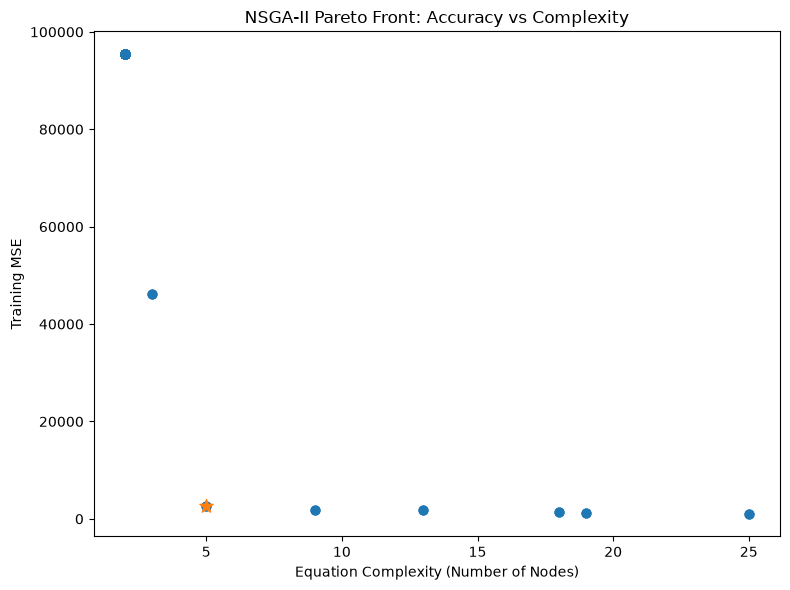

In [29]:
# PARETO FRONT PLOT
# ============================================================

plt.figure(figsize=(8, 6))

# Pareto points
plt.scatter(
    pareto_df["Equation_Length"],
    pareto_df["MSE"],
    s=40
)

# Highlight selected equation
plt.scatter(
    [len(selected_individual)],
    [selected_individual.fitness.values[0]],
    s=100,
    marker="*"
)

plt.xlabel("Equation Complexity (Number of Nodes)")
plt.ylabel("Training MSE")
plt.title("NSGA-II Pareto Front: Accuracy vs Complexity")

plt.tight_layout()
plt.savefig(
    RESULTS_PARETO_FIGURE,
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()


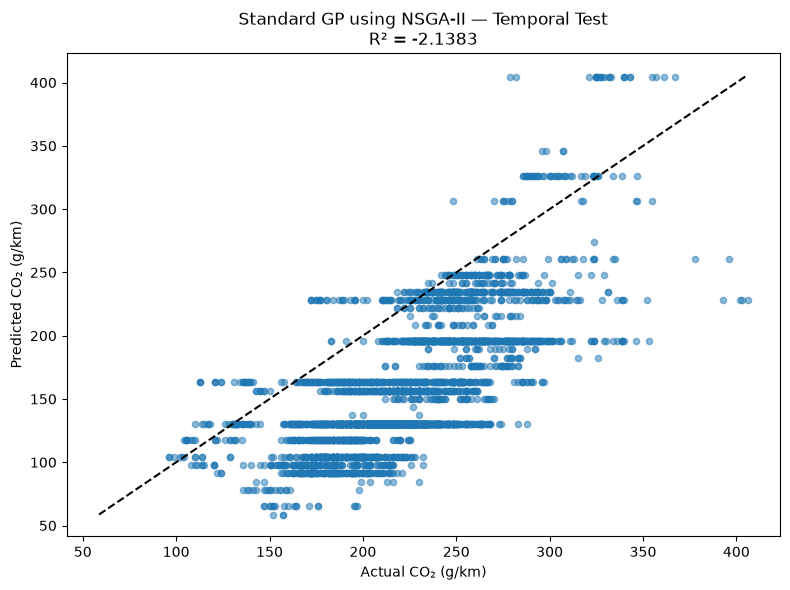

In [30]:
# PREDICTED VS ACTUAL PLOT
# ============================================================

plt.figure(figsize=(8, 6))

# Scatter: actual vs predicted
plt.scatter(
    y_new_np,
    y_new_pred,
    alpha=0.5,
    s=20
)

# 1:1 reference line
min_value = min(y_new_np.min(), y_new_pred.min())
max_value = max(y_new_np.max(), y_new_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "k--",
    linewidth=1.5
)

plt.xlabel("Actual CO₂ (g/km)")
plt.ylabel("Predicted CO₂ (g/km)")

plt.title(
    "Standard GP using NSGA-II — Temporal Test\n"
    f"R² = {test_r2:.4f}"
)

plt.tight_layout()

plt.savefig(
    RESULTS_FIGURE,
    format="pdf",
    bbox_inches="tight"
)

plt.show()
plt.close()

In [31]:
# FINAL MESSAGE
# ============================================================

print("\n" + "=" * 70)
print("STANDARD GP USING NSGA-II COMPLETE")
print("=" * 70)

print(f"Temporal Test R²: {test_r2:.4f}")
print(f"Temporal Test RMSE: {test_rmse:.4f}")
print(f"Temporal Test MAE: {test_mae:.4f}")
print()

print(f"5-Fold CV R²: {cv_r2_mean:.4f} ± {cv_r2_std:.4f}")
print(f"5-Fold CV RMSE: {cv_rmse_mean:.4f} ± {cv_rmse_std:.4f}")
print(f"5-Fold CV MAE: {cv_mae_mean:.4f} ± {cv_mae_std:.4f}")
print()

print(f"Equation length: {len(selected_individual)}")
print(f"Equation depth: {selected_individual.height}")
print(f"Pareto solutions: {len(pareto_front)}")
print()

print("Saved files:")
print(f" {RESULTS_TABLE}")
print(f" {RESULTS_EQUATION}")
print(f" {RESULTS_PARETO}")
print(f" {RESULTS_FIGURE}")
print(f" {RESULTS_PARETO_FIGURE}")



STANDARD GP USING NSGA-II COMPLETE
Temporal Test R²: -2.1383
Temporal Test RMSE: 72.9166
Temporal Test MAE: 66.0230

5-Fold CV R²: -0.9381 ± 1.1073
5-Fold CV RMSE: 64.3850 ± 19.8372
5-Fold CV MAE: 51.2665 ± 14.8278

Equation length: 5
Equation depth: 2
Pareto solutions: 500

Saved files:
 ../results/tables/standard_gp_nsga2_results.csv
 ../results/equations/standard_gp_nsga2_equation.txt
 ../results/equations/standard_gp_nsga2_pareto_front.csv
 ../results/figures/standard_gp_nsga2_predicted_actual.pdf
 ../results/figures/standard_gp_nsga2_pareto_front.pdf
